In [1]:
import torch
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import random
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report, roc_curve
import copy
import torch
import torch.optim as optim

from data_setup import TESSTransform, TESSDataset, create_dataloaders, get_clean_splits, make_dataloader
from torch.utils.data import DataLoader
from models import TESSModelV5, TESSModelV5Aux

In [2]:
RANDOM_SEED = 42

def set_seed(seed: int = 42):
    """Locks down all random number generators for strict reproducibility."""
    # 1. Set Python random seed
    random.seed(seed)
    
    # 2. Set Python environment seed
    os.environ['PYTHONHASHSEED'] = str(seed)
    
    # 3. Set NumPy seed
    np.random.seed(seed)
    
    # 4. Set PyTorch CPU seed
    torch.manual_seed(seed)
    
    # 5. Set PyTorch Apple Silicon (MPS) seed
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)
        
    # 6. Set PyTorch CUDA seeds (Standard practice to include for portability)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

In [3]:
device = "mps" if torch.backends.mps.is_available() else "cpu"

if device == 'mps':
    torch.mps.manual_seed(RANDOM_SEED)

device

'mps'

In [4]:
csv_path = "data/processed_labels_v2.csv"
data_dir = "data/lightcurves_v2"
BATCH_SIZE = 32

In [5]:
def accuracy_fn(y_true, y_pred):
    y_pred_rounded = torch.round(y_pred)
    
    y_true_int = y_true.cpu().int()
    y_pred_int = y_pred_rounded.cpu().int()
    
    correct = torch.eq(y_true_int, y_pred_int).sum().item() 
    
    acc = (correct / len(y_pred)) * 100 
    return acc

Dataset initialized with 1338 strictly synced samples.
Dataset initialized with 446 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
Epoch 0 | LR: 0.00100000 | Train Loss: 0.7276 Accuracy: 48.31% | Test Loss: 0.6903 Accuracy: 54.54% |Saved|
Epoch 1 | LR: 0.00100000 | Train Loss: 0.7122 Accuracy: 49.39% | Test Loss: 0.6857 Accuracy: 54.99% |Saved|
Epoch 3 | LR: 0.00100000 | Train Loss: 0.7101 Accuracy: 50.67% | Test Loss: 0.6839 Accuracy: 55.43% |Saved|
Epoch 4 | LR: 0.00100000 | Train Loss: 0.7000 Accuracy: 52.40% | Test Loss: 0.6823 Accuracy: 55.65% |Saved|
Epoch 5 | LR: 0.00100000 | Train Loss: 0.7030 Accuracy: 50.60% | Test Loss: 0.6802 Accuracy: 57.23% |Saved|
Epoch 6 | LR: 0.00100000 | Train Loss: 0.6925 Accuracy: 52.71% | Test Loss: 0.6792 Accuracy: 57.90% |Saved|
Epoch 8 | LR: 0.00100000 | Train Loss: 0.6941 Accuracy: 53.47% | Test Loss: 0.6770 Accuracy: 59.91% |Saved|
Epoch 9 | LR: 0.00100000 | Train Loss: 0.6934 Accuracy: 52.42% | Test Loss: 0.674

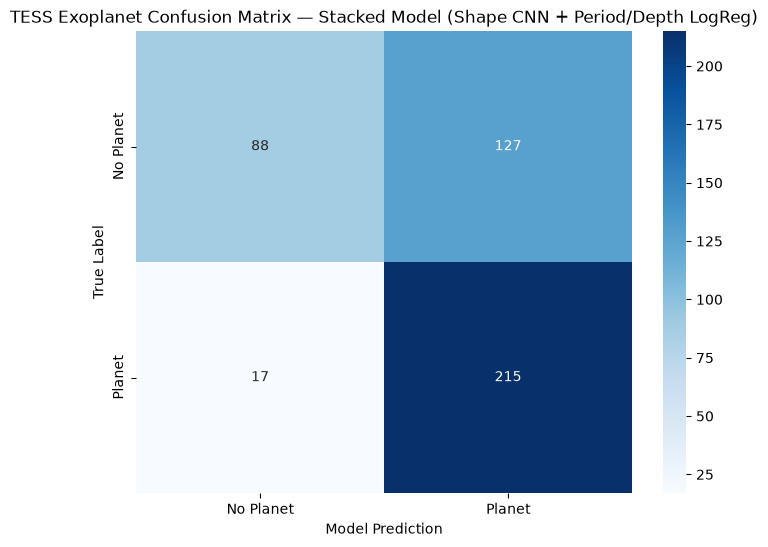

In [6]:
STACK_SEED = 42
set_seed(STACK_SEED)

# ---- Splits ----
train_df, test_df = get_clean_splits(csv_path, data_dir, aux_cols=["log_period", "log_depth"], seed=STACK_SEED)
train_base_df, train_meta_df = train_test_split(
    train_df, test_size=0.25, random_state=STACK_SEED, stratify=train_df["final_label"]
)
train_base_df = train_base_df.reset_index(drop=True)
train_meta_df = train_meta_df.reset_index(drop=True)

# ---- Base model A: shape-only CNN ----
train_base_loader = make_dataloader(train_base_df, data_dir, BATCH_SIZE, aux_cols=None, aux_stats=None,
                                     transform=TESSTransform(seed=STACK_SEED), shuffle=True, seed=STACK_SEED)
train_meta_loader_noaug = make_dataloader(train_meta_df, data_dir, BATCH_SIZE, aux_cols=None, aux_stats=None,
                                           transform=None, shuffle=False, seed=STACK_SEED)
test_loader_noaug = make_dataloader(test_df, data_dir, BATCH_SIZE, aux_cols=None, aux_stats=None,
                                     transform=None, shuffle=False, seed=STACK_SEED)

model_shape = TESSModelV5().to(device)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model_shape.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

epochs = 100
best_test_loss = float('inf')
best_model_weights = None
best_epoch = 0

for epoch in range(epochs):
    model_shape.train()
    train_loss, train_accuracy = 0, 0
    for X, y in train_base_loader:
        X, y = X.to(device), y.to(device)
        mean = X.mean(dim=2, keepdim=True); std = X.std(dim=2, keepdim=True)
        X = (X - mean) / (std + 1e-8)
        y = y.float().unsqueeze(dim=1)

        y_pred = model_shape(X)
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()
        train_accuracy += accuracy_fn(y_true=y, y_pred=torch.sigmoid(y_pred))

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    train_loss /= len(train_base_loader)
    train_accuracy /= len(train_base_loader)

    model_shape.eval()
    test_loss, test_accuracy = 0, 0
    with torch.inference_mode():
        for X_test, y_test in train_meta_loader_noaug:
            X_test, y_test = X_test.to(device), y_test.to(device)
            mean = X_test.mean(dim=2, keepdim=True); std = X_test.std(dim=2, keepdim=True)
            X_test = (X_test - mean) / (std + 1e-8)
            y_test = y_test.float().unsqueeze(dim=1)

            test_pred = model_shape(X_test)
            loss = loss_fn(test_pred, y_test)
            test_loss += loss.item()
            test_accuracy += accuracy_fn(y_true=y_test, y_pred=torch.sigmoid(test_pred))
        test_loss /= len(train_meta_loader_noaug)
        test_accuracy /= len(train_meta_loader_noaug)

    scheduler.step(test_loss)
    current_lr = optimizer.param_groups[0]['lr']

    # Checkpointing implementation
    if test_loss < best_test_loss:
        best_test_loss = test_loss
        best_test_accuracy = test_accuracy
        best_epoch = epoch
        best_model_weights = copy.deepcopy(model_shape.state_dict())
        checkpoint_msg = "|Saved|"
    else:
        checkpoint_msg = ""

    # Print only on checkpoint saves
    if checkpoint_msg:
        print(f"Epoch {epoch} | LR: {current_lr:.8f} | Train Loss: {train_loss:.4f} Accuracy: {train_accuracy:.2f}% | Test Loss: {test_loss:.4f} Accuracy: {test_accuracy:.2f}% {checkpoint_msg}")

print(f"\nBase model A (shape-only CNN) — best epoch: {best_epoch}, val loss: {best_test_loss:.4f}, val accuracy: {best_test_accuracy:.2f}%")
model_shape.load_state_dict(best_model_weights)
torch.save(best_model_weights, "model_shape_stacking_base.pt")

def get_probs_shape_only(model, loader):
    model.eval()
    probs = []
    with torch.inference_mode():
        for X, y in loader:
            X = X.to(device)
            mean = X.mean(dim=2, keepdim=True); std = X.std(dim=2, keepdim=True)
            X = (X - mean) / (std + 1e-8)
            p = torch.sigmoid(model(X)).squeeze().cpu().numpy()
            probs.extend(np.atleast_1d(p))
    return np.array(probs)

meta_shape_probs = get_probs_shape_only(model_shape, train_meta_loader_noaug)
test_shape_probs = get_probs_shape_only(model_shape, test_loader_noaug)

# ---- Base model B: period+depth logistic regression ----
scaler_b = StandardScaler()
Xb_train = scaler_b.fit_transform(train_base_df[["log_period", "log_depth"]])
clf_b = LogisticRegression(max_iter=1000).fit(Xb_train, train_base_df["final_label"])

meta_logreg_probs = clf_b.predict_proba(scaler_b.transform(train_meta_df[["log_period", "log_depth"]]))[:, 1]
test_logreg_probs = clf_b.predict_proba(scaler_b.transform(test_df[["log_period", "log_depth"]]))[:, 1]

# ---- Meta-classifier ----
meta_X_train = np.column_stack([meta_shape_probs, meta_logreg_probs])
#meta_clf = LogisticRegression().fit(meta_X_train, train_meta_df["final_label"])
meta_clf = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=STACK_SEED)
meta_clf.fit(meta_X_train, train_meta_df["final_label"])

meta_X_test = np.column_stack([test_shape_probs, test_logreg_probs])
#final_probs = meta_clf.predict_proba(meta_X_test)[:, 1]
final_preds_direct = meta_clf.predict(meta_X_test)
final_probs = meta_clf.predict_proba(meta_X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(test_df["final_label"], final_probs)
opt_threshold = thresholds[np.argmax(tpr - fpr)]
final_preds = (final_probs >= opt_threshold).astype(int)

print(f"\nOptimal threshold: {opt_threshold:.3f}")
print(classification_report(test_df["final_label"], final_preds, target_names=["No Planet (0)", "Planet (1)"]))
print("Meta-classifier weights [shape_cnn, logreg]:", meta_clf.feature_importances_)

cm = confusion_matrix(test_df["final_label"], final_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Planet', 'Planet'], yticklabels=['No Planet', 'Planet'])
plt.title("TESS Exoplanet Confusion Matrix — Stacked Model (Shape CNN + Period/Depth LogReg)")
plt.ylabel("True Label")
plt.xlabel("Model Prediction")
plt.show()

In [7]:
from sklearn.tree import export_text
print(export_text(meta_clf, feature_names=["shape_prob", "logreg_prob"]))

|--- shape_prob <= 0.50
|   |--- shape_prob <= 0.27
|   |   |--- class: 0
|   |--- shape_prob >  0.27
|   |   |--- logreg_prob <= 0.46
|   |   |   |--- class: 0
|   |   |--- logreg_prob >  0.46
|   |   |   |--- class: 1
|--- shape_prob >  0.50
|   |--- shape_prob <= 0.59
|   |   |--- shape_prob <= 0.57
|   |   |   |--- class: 1
|   |   |--- shape_prob >  0.57
|   |   |   |--- class: 0
|   |--- shape_prob >  0.59
|   |   |--- shape_prob <= 0.64
|   |   |   |--- class: 1
|   |   |--- shape_prob >  0.64
|   |   |   |--- class: 1



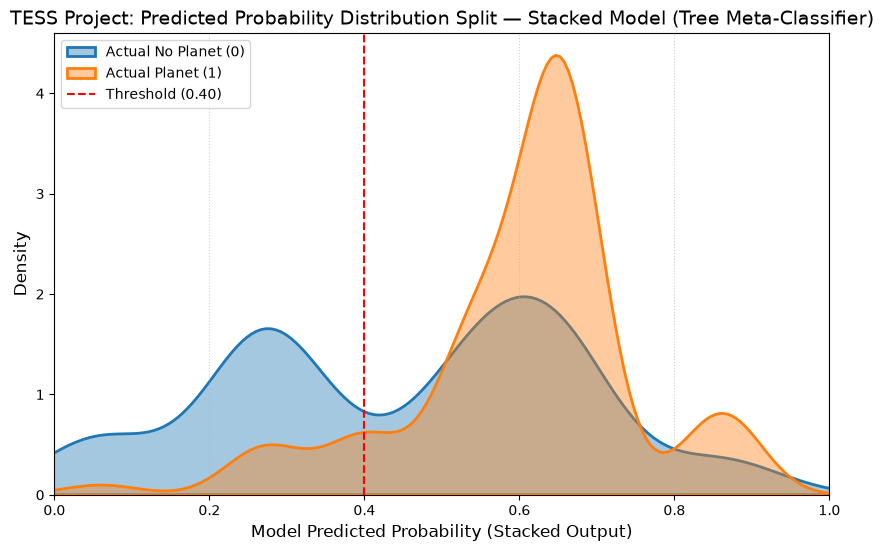

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

probs_arr = np.array(final_probs)
true_arr = np.array(test_df["final_label"])

plt.figure(figsize=(10, 6))

sns.kdeplot(probs_arr[true_arr == 0], label='Actual No Planet (0)', fill=True, alpha=0.4, linewidth=2)
sns.kdeplot(probs_arr[true_arr == 1], label='Actual Planet (1)', fill=True, alpha=0.4, linewidth=2)

plt.axvline(x=opt_threshold, color='red', linestyle='--', label=f'Threshold ({opt_threshold:.2f})')

plt.title('TESS Project: Predicted Probability Distribution Split — Stacked Model (Tree Meta-Classifier)', fontsize=14)
plt.xlabel('Model Predicted Probability (Stacked Output)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.xlim(0, 1)
plt.legend(loc='upper left')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.show()